In [1]:
import pandas as pd
import numpy as np

In [25]:
hp = pd.read_csv('House_Price_dataset.csv')
hp

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,yes,no,yes,no,no,2.0,no,unfurnished
541,1767150,2400,3.0,1.0,1.0,no,no,no,no,no,0.0,no,semi-furnished
542,1750000,3620,2.0,1.0,1.0,yes,no,no,no,no,0.0,no,unfurnished
543,1750000,2910,3.0,1.0,1.0,no,no,no,no,no,0.0,no,furnished


In [4]:
hp.isna().sum()


price               0
area                0
bedrooms            5
bathrooms           5
stories             2
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             4
prefarea            0
furnishingstatus    0
dtype: int64

In [5]:
 hp = hp.fillna(hp.median(numeric_only=True))

In [6]:
hp.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [7]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
hp["mainroad"] = le.fit_transform(hp["mainroad"])
hp["guestroom"] = le.fit_transform(hp["guestroom"])
hp["basement"] = le.fit_transform(hp["basement"])
hp["hotwaterheating"] = le.fit_transform(hp["hotwaterheating"])
hp["airconditioning"] = le.fit_transform(hp["airconditioning"])
hp["prefarea"] = le.fit_transform(hp["prefarea"])
hp

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,furnished
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,furnished
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,semi-furnished
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,furnished
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,1,0,1,0,0,2.0,0,unfurnished
541,1767150,2400,3.0,1.0,1.0,0,0,0,0,0,0.0,0,semi-furnished
542,1750000,3620,2.0,1.0,1.0,1,0,0,0,0,0.0,0,unfurnished
543,1750000,2910,3.0,1.0,1.0,0,0,0,0,0,0.0,0,furnished


In [8]:
hp['furnishingstatus'] = hp['furnishingstatus'].replace(to_replace=['unfurnished', 'semi-furnished', 'furnished'], value=[0,1,2])
hp

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,2
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,2
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,2
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,1,0,1,0,0,2.0,0,0
541,1767150,2400,3.0,1.0,1.0,0,0,0,0,0,0.0,0,1
542,1750000,3620,2.0,1.0,1.0,1,0,0,0,0,0.0,0,0
543,1750000,2910,3.0,1.0,1.0,0,0,0,0,0,0.0,0,2


In [9]:
from sklearn.model_selection import train_test_split
X = hp['area']
y= hp['price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [10]:
print(X_train, X_test, y_train, y_test)

46     6000
93     7200
335    3816
412    2610
471    3750
       ... 
71     6000
106    5450
270    4500
435    4040
102    5500
Name: area, Length: 436, dtype: int64 316    5900
77     6500
360    4040
90     5000
493    3960
       ... 
15     6000
357    6930
39     6000
54     6000
155    6100
Name: area, Length: 109, dtype: int64 46     7525000
93     6300000
335    3920000
412    3430000
471    3010000
        ...   
71     6755000
106    6160000
270    4340000
435    3290000
102    6195000
Name: price, Length: 436, dtype: int64 316    4060000
77     6650000
360    3710000
90     6440000
493    2800000
        ...   
15     9100000
357    3773000
39     7910000
54     7350000
155    5530000
Name: price, Length: 109, dtype: int64


In [11]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression()

In [12]:
x_train1 = X_train.to_frame()
x_test1 = X_test.to_frame()
y_train1 = y_train.to_frame()
y_test1 = y_test.to_frame()

In [13]:
reg = LinearRegression().fit(x_train1,y_train1)

In [14]:
reg.coef_

array([[425.72984194]])

In [15]:
y_pred = reg.predict(x_test1)

In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
mse = mean_squared_error(y_test1, y_pred)
mae = mean_absolute_error(y_test1, y_pred)
r2 = r2_score(y_test1, y_pred)
print("MSE : ", mse)
print("MAE : ", mae)
print("R2 Score : ", r2)

MSE :  3675286604768.185
MAE :  1474748.1337969352
R2 Score :  0.27287851871974644


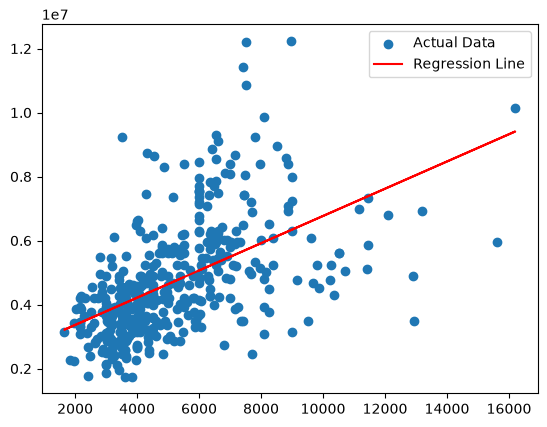

In [17]:
import matplotlib.pyplot as plt
y_pred1 = reg.predict(x_train1)
plt.scatter(x_train1,y_train1, label = 'Actual Data')
plt.plot(x_train1,y_pred1,color = 'red', label = 'Regression Line')
plt.legend()


In [18]:
lX = hp.drop(columns=['price'])
ly= hp['price']

lX_train, lX_test, ly_train, ly_test = train_test_split(
    lX,
    ly,
    test_size=0.20,
    random_state=42
)
lr = LinearRegression()
lr.fit(lX_train, ly_train)
ly_pred = lr.predict(lX_test)


In [19]:
linear_mse = mean_squared_error(ly_test, ly_pred)
linear_mae = mean_absolute_error(ly_test, ly_pred)
linear_r2 = r2_score(ly_test, ly_pred)

print("MSE:", linear_mse)
print("MAE:", linear_mae)
print("R2 Score:", linear_r2)

MSE: 1762261595678.3098
MAE: 974800.4763575832
R2 Score: 0.6513528332210876


In [20]:
pX = hp.drop(columns=['price'])
py = hp['price']

pX_train, pX_test, py_train, py_test = train_test_split(pX, py, test_size=0.2, random_state=42)

from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)
pX_train = poly.fit_transform(pX_train)
pX_test = poly.fit_transform(pX_test)

In [21]:
pr = LinearRegression()
pr.fit(pX_train, py_train)
py_pred = pr.predict(pX_test)

p_mse = mean_squared_error(py_test, py_pred)
p_mae = mean_absolute_error(py_test, py_pred)
p_r2 = r2_score(py_test, py_pred)

print("P_MSE:", p_mse)
print("P_MAE:", p_mae)
print("P_R2 Score:", p_r2)

P_MSE: 1761881279841.5505
P_MAE: 1008480.6960570427
P_R2 Score: 0.6514280751938416


In [22]:
area = float(input("Enter area: "))
bedrooms = int(input("Enter bedrooms: "))
bathrooms = int(input("Enter bathrooms: "))
stories = int(input("Enter stories: "))

mainroad = int(input("Mainroad (0=No, 1=Yes): "))
guestroom = int(input("Guestroom (0=No, 1=Yes): "))
basement = int(input("Basement (0=No, 1=Yes): "))

hotwaterheating = int(input("Hot water heating (0=No, 1=Yes): "))
airconditioning = int(input("Air conditioning (0=No, 1=Yes): "))

parking = int(input("Parking spaces (0-3): "))
prefarea = int(input("Preferred area (0=No, 1=Yes): "))

print("Furnishing Status:")
print("0 = Unfurnished")
print("1 = Semi-Furnished")
print("2 = Furnished")

furnishingstatus = int(input("Enter furnishing status: "))


Enter area:  3540
Enter bedrooms:  3
Enter bathrooms:  2
Enter stories:  2
Mainroad (0=No, 1=Yes):  0
Guestroom (0=No, 1=Yes):  1
Basement (0=No, 1=Yes):  1
Hot water heating (0=No, 1=Yes):  1
Air conditioning (0=No, 1=Yes):  0
Parking spaces (0-3):  2
Preferred area (0=No, 1=Yes):  1


Furnishing Status:
0 = Unfurnished
1 = Semi-Furnished
2 = Furnished


Enter furnishing status:  1


In [23]:
data1 = pd.DataFrame([
    [area, bedrooms, bathrooms, stories, mainroad, guestroom,
     basement, hotwaterheating, airconditioning, parking,
     prefarea, furnishingstatus]
], columns=[
    'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
    'guestroom', 'basement', 'hotwaterheating',
    'airconditioning', 'parking', 'prefarea',
    'furnishingstatus'
])


In [24]:
poly_prediction = pr.predict(poly.fit_transform(data1))
print("Predicted House Price:", poly_prediction[0])

Predicted House Price: 5132472.745712715
